#Install

In [ ]:
!pip install pymupdf
!pip install pytesseract
!pip install -U langchain-community

!apt-get update
!apt-get install -y tesseract-ocr
!pip install pytesseract

!pip install pypdf

In [ ]:
import pandas as pd
# from read_pdf import read_pdf_and_clean
import pandas as pd
from tqdm import tqdm
from openai import OpenAI

In [ ]:
import pickle

with open("/content/drive/MyDrive/fix_systematic_review/134_texts.pkl", "rb") as f:
    file_texts = pickle.load(f)


In [ ]:
read_file = "/content/drive/MyDrive/fix_systematic_review/MMAT/q2_jugment_1.xlsx" # Path to save progress file
df = pd.read_excel(read_file)
df["decision_extracted_q2"] = df["jugment_Q2"].str.extract(r"Decision:\s*([A-Za-z])")


In [ ]:
import pandas as pd


def determine_final_q2(row):
    answer = row['decision_extracted_q2']
    if answer == 'A':
        return row.get('Answering_Q2', None)
    elif answer == 'B':
        return row.get('Answering_Q2_llama', None)
    else:
        return row.get('Answering_Q2_llama', None)

df['final_q2'] = df.apply(determine_final_q2, axis=1)


In [ ]:
df.final_q2.value_counts()

,count
final_q2,
Yes,122
No,12


In [ ]:
df= df[df['final_q2'] == 'Yes']
df

,Unnamed: 0,PubMed ID,DOI,Title,Year,Abstract,Author Keywords,english,response,response_systematic,...,type_agreement_Q1,jugment_q1,decision_extracted,Q1_final,Response_Q2_llama,Answering_Q2_llama,Q2_agreement,jugment_Q2,decision_extracted_q2,final_q2
0,2,18710376.0,10.1111/j.1365-2702.2007.02040.x,The spectrum of barriers to and facilitators o...,2008,The focus of the study is the identification o...,[],en,included,Decision: No \nExplain: The study is an empir...,...,1,NaN,NaN,Yes,Answer: Yes\nExplanation: The study collected ...,Yes,1,NaN,NaN,Yes
1,3,15761309.0,10.1097/00005110-200503000-00005,Overcoming barriers and promoting the use of r...,2005,To identify changes in nurse attitudes toward ...,[],en,included,Decision: No\n\nExplain: The study described i...,...,1,NaN,NaN,Yes,Answer: Yes\nExplanation: The study collected ...,Yes,1,NaN,NaN,Yes
2,4,19040688.0,10.1111/j.1365-2648.2008.04878.x,"Nursing practice, knowledge, attitudes and per...",2009,This paper is a report of a study to describe ...,[],en,included,Decision: No\n\nExplain: The study described i...,...,1,NaN,NaN,Yes,Answer: Yes\nExplanation: The study collected ...,Yes,1,NaN,NaN,Yes
3,5,7844284.0,10.1016/s8755-7223(95)80073-5,"Information-seeking, research utilization, and...",1995,This study used Roger's diffusion of innovatio...,[],en,included,Decision: No\n\nExplain: The study described i...,...,1,NaN,NaN,Yes,Answer: Yes\nExplanation: The study collected ...,Yes,1,NaN,NaN,Yes
4,6,15317513.0,10.1111/j.1365-2702.2004.00941.x,Perceived barriers and facilitators to impleme...,2004,Studies have consistently demonstrated that nu...,[],en,included,Decision: No\n\nExplain: The study described i...,...,1,NaN,NaN,Yes,Answer: Yes\nExplanation: The study collected ...,Yes,1,NaN,NaN,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,172,NaN,10.1177/1744987110387484,Graduate nurses' and midwives' perceptions of ...,2011,An increasing amount of quantitative research ...,Graduate nurses; Qualitative research; Researc...,en,included,Decision: No \nExplain: The study described i...,...,1,NaN,NaN,Yes,Answer: Yes\nExplanation: The study collected ...,Yes,1,NaN,NaN,Yes
129,176,NaN,10.1108/eb020875,Research utilization in nursing: Barriers and ...,1998,This paper describes a recent study which inve...,NaN,en,included,Decision: No \nExplain: The study described i...,...,1,NaN,NaN,Yes,Answer: Yes\nExplanation: The study collected ...,Yes,1,NaN,NaN,Yes
131,178,9791311.0,NaN,Nephrology nurses' perceptions of barriers and...,1998,The purpose of this study was to determine nep...,[],en,included,Decision: No\n\nExplain: The study described i...,...,1,NaN,NaN,Yes,Answer: Yes\nExplanation: The study collected ...,Yes,1,NaN,NaN,Yes
132,179,17892348.0,NaN,Access to and use of research by rural nurses,2007,The use of relevant research findings to infor...,[],en,included,Decision: No\n\nExplain: The study described i...,...,1,NaN,NaN,Yes,Answer: Yes\nExplanation: The study collected ...,Yes,1,NaN,NaN,Yes


#Read Files

In [ ]:
# Set the source directory and collect all PDF files
from pathlib import Path
path = '/content/drive/MyDrive/fix_systematic_review/papers_2'
source_dir = Path(path)
pdf_files = list(source_dir.glob('*.pdf'))

# Create a mapping between cleaned filenames (e.g., derived from DOI or title)
# and the original filename (without the .pdf extension)
cleaned_to_path = {}

for f in pdf_files:
    original_name = f.stem  # Get the filename without .pdf
    cleaned_name = (
        original_name
        .replace("_2F", "/")
        # .replace("_", " ")
        .replace(":", "")
        .replace("_28", "(")
        .replace("_29", ")")
        .replace("_", "\'")
        .lower()
    )
    cleaned_to_path[cleaned_name] = f.stem


In [ ]:
file_texts = {}
for i, row in tqdm(df.iterrows(), total=len(df)):
    match = str(row.get("Matching_Filename")).lower()
    name = row.get("Matching_Filename")
    if match in cleaned_to_path:
        file_path = f"{path}/{cleaned_to_path[match]}.pdf"
        # print(filepath)
        docs = read_pdf_and_clean(file_path)
        pages_text = "\n".join([doc.page_content for doc in docs])
        file_texts[name] = pages_text
    else:
        print(match)

In [ ]:
file_path = '/content/drive/MyDrive/fix_systematic_review/papers_2/Implementing Best Practice Guidelines under the Best Practice Spotlight Organisation Facilitators and Barriers for Nurses A Delphi Study.pdf'
docs = read_pdf_and_clean(file_path)
pages_text = "\n".join([doc.page_content for doc in docs])
name = df.iloc[109].Matching_Filename
file_texts[name] = pages_text


✅ Text layer found. Using PyPDFLoader...


#Prompt

In [ ]:
test_for_all = """
You are a systematic review expert.
Your task is to find the type of article from the following five: Qualitative, Quantitative_descriptive,Mixed_methods, RCT, Quantitative_non_randomized

# Text to evaluate:
{text}

# Criteria for a qualitative study:
• The text focuses on understanding the meanings individuals or groups assign to a problem.
• The text uses non-numerical data (e.g., interviews, focus groups, observations).
• The text describes an inductive, interpretive, and flexible research approach.
• A small, purposefully selected sample is described.
• The analysis described in the text does not include any quantitative data.

# Criteria for a quantitative descriptive study:
• Numerical data are collected and analyzed to describe characteristics or trends.
• No variables are manipulated.
• No intervention is tested; the study reports observed phenomena only.
• Descriptive statistics are used (e.g., means, frequencies, percentages).
• No qualitative data or analysis is presented (e.g., no interviews, thematic interpretation, or participant narratives).

# Criteria for a mixed methods study:
• The study integrates both qualitative and quantitative approaches.
• Both numerical and non-numerical data are collected.
• The analysis includes both qualitative and quantitative components.
• Findings from both strands are integrated to address complex or multi-faceted research questions.

# Criteria for an RCT:
• Participants are randomly allocated to treatment and control groups.
• Numerical data are used to assess the intervention’s impact.
• A true experimental design is described (at least one variable is manipulated and others are controlled).
• The study focuses on establishing causality.
• There is sufficient methodological detail to confirm an RCT design.

# Criteria for a Quantitative_non_randomized:
• Quantitative approach using numerical data.
• No random assignment of participants to groups.
• There is a clear intervention, treatment, or exposure being studied.
• OR there is an explicit comparison between pre-defined groups (e.g., before vs after, intervention group vs control group).
• At least one variable is manipulated or compared across groups.
⚠️ Important: Surveys or questionnaires **alone**, without any intervention or comparison between groups, do **not qualify** as quantitative non-randomized studies. They are typically classified as quantitative descriptive studies.


Choose only one of the five options.
Answer: <Article Type>
Explanation: <Content of Explanation>
"""

#gpt-4o-mini

In [ ]:

# Iterate with progress bar
client = OpenAI(api_key="Api_key")

df['Response_Type'] = None
for index, row in tqdm(df.iterrows(), total=len(df), desc="Processing abstracts"):

    # Skip rows with existing responses
    if pd.notnull(row['Response_Type']):
        continue
    name = row.Matching_Filename

    text = file_texts[name]

    full_prompt = test_for_all.format(text = text)


    # Call OpenAI API
    response = client.chat.completions.create(
        model="gpt-4o-mini",
        temperature=0,
        max_tokens=2048,
        top_p=0.45,
        messages=[
            {"role": "user", "content": full_prompt}
        ]
    )

    # Extract and store response
    content = response.choices[0].message.content
    print(content)
    df.at[index, 'Response_Type'] = content

In [ ]:
df["Type"] = df["Response_Type"].str.extract(r'Answer:\s*(Quantitative_descriptive|Qualitative|Quantitative_non_randomized|Mixed_methods|RCT|Quantitative_randomized_controlled_trials)', expand=False)


/tmp/ipython-input-3544468748.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Type"] = df["Response_Type"].str.extract(r'Answer:\s*(Quantitative_descriptive|Qualitative|Quantitative_non_randomized|Mixed_methods|RCT|Quantitative_randomized_controlled_trials)', expand=False)


In [ ]:
df.to_excel('/content/drive/MyDrive/fix_systematic_review/MMAT/Type_new_gp_1t.xlsx')

#Llama

In [ ]:
# df = pd.read_excel('/content/drive/MyDrive/fix_systematic_review/MMAT/Type.xlsx')
# df

In [ ]:
import os
import requests
import json

# Store your API key as an environment variable for safety:
OPENROUTER_API_KEY = 'Api_Key'
OPENROUTER_URL = "https://openrouter.ai/api/v1/chat/completions"

HEADERS = {
    "Authorization": f"Bearer {OPENROUTER_API_KEY}",
    "Content-Type": "application/json",
    # Optional but recommended: helps OpenRouter show where requests come from
    "HTTP-Referer": "https://your-site-or-none.example",
    "X-Title": "Your App Name",
}

def call_openai_new(prompt, model="meta-llama/llama-3.3-70b-instruct", #"google/gemini-2.5-flash-lite"
                temperature=0, top_p=0.45, max_tokens=2048, timeout=60):
    """
    Replacement function for OpenAI client -> uses OpenRouter API.

    Args:
        prompt (str): user input text
        model (str): model to use (default Gemini Flash Lite)
        temperature (float): sampling temperature
        top_p (float): nucleus sampling
        max_tokens (int): maximum output tokens
        timeout (int): request timeout in seconds

    Returns:
        str: model's response content or error message
    """
    try:
        payload = {
            "model": model,
            "messages": [
                {"role": "user", "content": prompt}
            ],
            "temperature": temperature,
            "top_p": top_p,
            "max_tokens": max_tokens,
        }

        resp = requests.post(OPENROUTER_URL, headers=HEADERS,
                             data=json.dumps(payload), timeout=timeout)
        resp.raise_for_status()  # raises HTTPError if status != 200
        data = resp.json()

        # OpenRouter returns a format similar to OpenAI
        return data["choices"][0]["message"]["content"].strip()

    except requests.HTTPError as e:
        # Try to parse error body for more details
        try:
            err_body = resp.json()
        except Exception:
            err_body = resp.text
        return f"Error {resp.status_code}: {err_body}"
    except Exception as e:
        return f"Error: {e}"


In [ ]:
output_file = '/content/drive/MyDrive/fix_systematic_review/MMAT/Type_llama_new_1.xlsx'


In [ ]:

text_col = "Matching_Filename"
df['Type_llama'] = ''
save_interval = 10

for i, row in tqdm(df.iterrows(), total=len(df), desc="Processing rows"):
    number_id = row.get(text_col, None) # Get filename for this row
    # if pd.notnull(row['Type_llama']):
    #     continue

    prompt = test_for_all.format(text=file_texts[number_id])
    # Send prompt to the model and get the result
    result = call_openai_new(prompt)



    # Save the result in the corresponding MMAT_Q column
    df.at[i, "Type_llama"] = result

    # Save progress every 'save_interval' rows
    if i % save_interval == 0 and i > 0:
        df.to_excel(output_file, index=False)
        print(f"💾 Progress saved at row {i} to {output_file}")
# Final save after processing all rows
df.to_excel(output_file, index=False)
print(f"✅ Processing completed. Final file saved to {output_file}")


In [ ]:
# df["Type_llama_only_response"] = df["Type_llama"].str.extract(
#     r'(?:Article Type:|Answer:)\s*(Quantitative_descriptive|Qualitative|Quantitative_non_randomized|Mixed_methods|RCT|Quantitative_randomized_controlled_trials)',
#     expand=False
# )
# df["Type_llama_only_response"] = df["Type_llama"].str.extract(
#     r'(?:Article Type:|Answer:|I conclude that this study is a:?\s*\*\*?)\s*(Quantitative_descriptive|Qualitative|Quantitative_non_randomized|Mixed_methods|RCT|Quantitative_randomized_controlled_trials)',
#     expand=False
# )
# df["Type_llama_only_response"] = df["Type_llama"].str.extract(
#     r'(?:Article Type:|Answer:|I conclude that (?:this study|the article) (?:is|type is):?\s*\*{0,2})\s*(Quantitative_descriptive|Qualitative|Quantitative_non_randomized|Mixed_methods|RCT|Quantitative_randomized_controlled_trials)',
#     expand=False
# )
df["Type_llama_only_response"] = df["Type_llama"].str.extract(
    r'(?:Article Type:|Answer:|I conclude that (?:this study|the article) (?:is(?: a)?|type is):?\s*\n?\**)?\s*(Quantitative_descriptive|Qualitative|Quantitative_non_randomized|Mixed_methods|RCT|Quantitative_randomized_controlled_trials)',
    expand=False
)

df

In [ ]:
df["Type_agreement"] = (df["Type"] == df["Type_llama_only_response"]).astype(int)


/tmp/ipython-input-3074748270.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Type_agreement"] = (df["Type"] == df["Type_llama_only_response"]).astype(int)


In [ ]:
total_agreed = df["Type_agreement"].sum()
print(f"Number of agreements: {total_agreed} out of {len(df)}")


Number of agreements: 99 out of 122


In [ ]:
agreed_types = df[df["Type_agreement"] == 1]["Type"].value_counts()
print("Agreed types breakdown:\n", agreed_types)


Agreed types breakdown:
 Type
Quantitative_descriptive       64
Qualitative                    17
Mixed_methods                  12
Quantitative_non_randomized     5
RCT                             1
Name: count, dtype: int64


In [ ]:
agreed_df = df[df["Type_agreement"] == 1]

sampled_df = agreed_df.groupby("Type").apply(lambda x: x.sample(n=min(len(x), 10), random_state=42)).reset_index(drop=True)
sampled_df.to_excel('/content/drive/MyDrive/fix_systematic_review/MMAT/label_type/Type_agreement_1.xlsx')

/tmp/ipython-input-1107735950.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_df = agreed_df.groupby("Type").apply(lambda x: x.sample(n=min(len(x), 10), random_state=42)).reset_index(drop=True)


In [ ]:
df[df['Matching_Filename']=='10.1097/NNA.0b013e3182786029']['Type_agreement']

,Type_agreement
43,1





#Jugment - Claude

In [ ]:
import os
import requests
import json

# Store your API key as an environment variable for safety:
OPENROUTER_API_KEY = 'Api_key'
OPENROUTER_URL = "https://openrouter.ai/api/v1/chat/completions"

HEADERS = {
    "Authorization": f"Bearer {OPENROUTER_API_KEY}",
    "Content-Type": "application/json",
    # Optional but recommended: helps OpenRouter show where requests come from
    "HTTP-Referer": "https://your-site-or-none.example",
    "X-Title": "Your App Name",
}

def call_openai_new(prompt, model="anthropic/claude-sonnet-4", #"google/gemini-2.5-flash-lite"
                temperature=0, top_p=0.45, max_tokens=2048, timeout=60):
    """
    Replacement function for OpenAI client -> uses OpenRouter API.

    Args:
        prompt (str): user input text
        model (str): model to use (default Gemini Flash Lite)
        temperature (float): sampling temperature
        top_p (float): nucleus sampling
        max_tokens (int): maximum output tokens
        timeout (int): request timeout in seconds

    Returns:
        str: model's response content or error message
    """
    try:
        payload = {
            "model": model,
            "messages": [
                {"role": "user", "content": prompt}
            ],
            "temperature": temperature,
            "top_p": top_p,
            "max_tokens": max_tokens,
        }

        resp = requests.post(OPENROUTER_URL, headers=HEADERS,
                             data=json.dumps(payload), timeout=timeout)
        resp.raise_for_status()  # raises HTTPError if status != 200
        data = resp.json()

        # OpenRouter returns a format similar to OpenAI
        return data["choices"][0]["message"]["content"].strip()

    except requests.HTTPError as e:
        # Try to parse error body for more details
        try:
            err_body = resp.json()
        except Exception:
            err_body = resp.text
        return f"Error {resp.status_code}: {err_body}"
    except Exception as e:
        return f"Error: {e}"


In [ ]:
prompt_template = """
You are an impartial judge in a systematic review evaluation task.

Text to evaluate:
{text}

Task:
(
To find the type of article from the following five: Qualitative, Quantitative_descriptive,Mixed_methods, RCT, Quantitative_non_randomized


# Criteria for a qualitative study:
• The text focuses on understanding the meanings individuals or groups assign to a problem.
• The text uses non-numerical data (e.g., interviews, focus groups, observations).
• The text describes an inductive, interpretive, and flexible research approach.
• A small, purposefully selected sample is described.
• The analysis described in the text does not include any quantitative data.

# Criteria for a quantitative descriptive study:
• Numerical data are collected and analyzed to describe characteristics or trends.
• No variables are manipulated.
• No intervention is tested; the study reports observed phenomena only.
• Descriptive statistics are used (e.g., means, frequencies, percentages).
• No qualitative data or analysis is presented (e.g., no interviews, thematic interpretation, or participant narratives).

# Criteria for a mixed methods study:
• The study integrates both qualitative and quantitative approaches.
• Both numerical and non-numerical data are collected.
• The analysis includes both qualitative and quantitative components.
• Findings from both strands are integrated to address complex or multi-faceted research questions.

# Criteria for an RCT:
• Participants are randomly allocated to treatment and control groups.
• Numerical data are used to assess the intervention’s impact.
• A true experimental design is described (at least one variable is manipulated and others are controlled).
• The study focuses on establishing causality.
• There is sufficient methodological detail to confirm an RCT design.

# Criteria for a Quantitative_non_randomized:
• Quantitative approach using numerical data.
• No random assignment of participants to groups.
• There is a clear intervention, treatment, or exposure being studied.
• OR there is an explicit comparison between pre-defined groups (e.g., before vs after, intervention group vs control group).
• At least one variable is manipulated or compared across groups.
⚠️ Important: Surveys or questionnaires **alone**, without any intervention or comparison between groups, do **not qualify** as quantitative non-randomized studies. They are typically classified as quantitative descriptive studies.


Model A's Answer:
{answer_a}

Model B's Answer:
{answer_b}

Your role:
- Carefully compare both answers against the provided text and the task.
- Decide which model's answer (A or B) is more accurate and justified.

Respond in the exact format:
Decision: <A or B >
Reasoning: <One to three sentences explaining why you made this decision>
"""


In [ ]:

from tqdm import tqdm
output_file = "/content/drive/MyDrive/fix_systematic_review/MMAT/Type_progress_jugment_new.xlsx"  # Path to save progress file
df['jugment_type'] = None
# Loop over DataFrame rows with tqdm progress bar
save_interval =10
text_col = "Matching_Filename"

for i, row in tqdm(df.iterrows(), total=len(df), desc="Processing rows"):
    number_id = row.get(text_col, None) # Get filename for this row


    if row.get(f"Type_agreement", None) == 1:
      continue

    gpt = row.get(f"Response_Type", None)
    llama = row.get(f"Type_llama", None)

    prompt = prompt_template.format(text=file_texts[number_id],answer_a =gpt,answer_b = llama )
        # Send prompt to the model and get the result
    result = call_openai_new(prompt)
    df.at[i, f'jugment_type'] = result

        # Save progress every 'save_interval' rows
    if i % save_interval == 0 and i > 0:
        df.to_excel(output_file, index=False)
        print(f"💾 Progress saved at row {i} to {output_file}")

# Final save after processing all rows
df.to_excel(output_file, index=False)
print(f"✅ Processing completed. Final file saved to {output_file}")

In [ ]:
# import pandas as pd
# output_file = "/content/drive/MyDrive/fix_systematic_review/MMAT/Type_progress_jugment.xlsx"  # Path to save progress file
# df = pd.read_excel(output_file)

In [ ]:
df["decision_extracted"] = df["jugment_type"].str.extract(r"Decision:\s*([A-Za-z])")

df

In [ ]:
decision_counts = df["decision_extracted"].value_counts()
print("Decision Summary:")
print(decision_counts)

Decision Summary:
decision_extracted
A    14
B     9
Name: count, dtype: int64


In [ ]:
df[df['Type_agreement'] == 0].to_excel('/content/drive/MyDrive/fix_systematic_review/MMAT/label_type/notagree_23_type.xlsx')

In [ ]:
# agreed_df = df[df['type_agreement'] == 1]

# sampled = (
#     agreed_df.groupby("Type", group_keys=False)
#     .apply(lambda x: x.sample(n=min(10, len(x)), random_state=42))
# )

# # sampled[["Title", "Type", "Type_llama_only_response"]]
# sampled.to_excel('sample_50_type.xlsx')

/tmp/ipython-input-3405542672.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min(10, len(x)), random_state=42))


In [ ]:
# not_agreed_df = df[df['type_agreement'] == 0]
# not_agreed_df.to_excel('notagree_20_type.xlsx')

In [ ]:
df['Type_final'] = df['Type']
df.loc[df['Type_agreement'] == 0, 'Type_final'] = df.loc[df['Type_agreement'] == 0, 'Type_llama_only_response']
for i,row in df.iterrows():
  if row['Type_agreement'] == 0:
    res = row['decision_extracted']
    if res == 'A':
      df.at[i, 'Type_final'] = row['Type']
    else:
      df.at[i, 'Type_final'] = row['Type_llama_only_response']


/tmp/ipython-input-4039792860.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Type_final'] = df['Type']


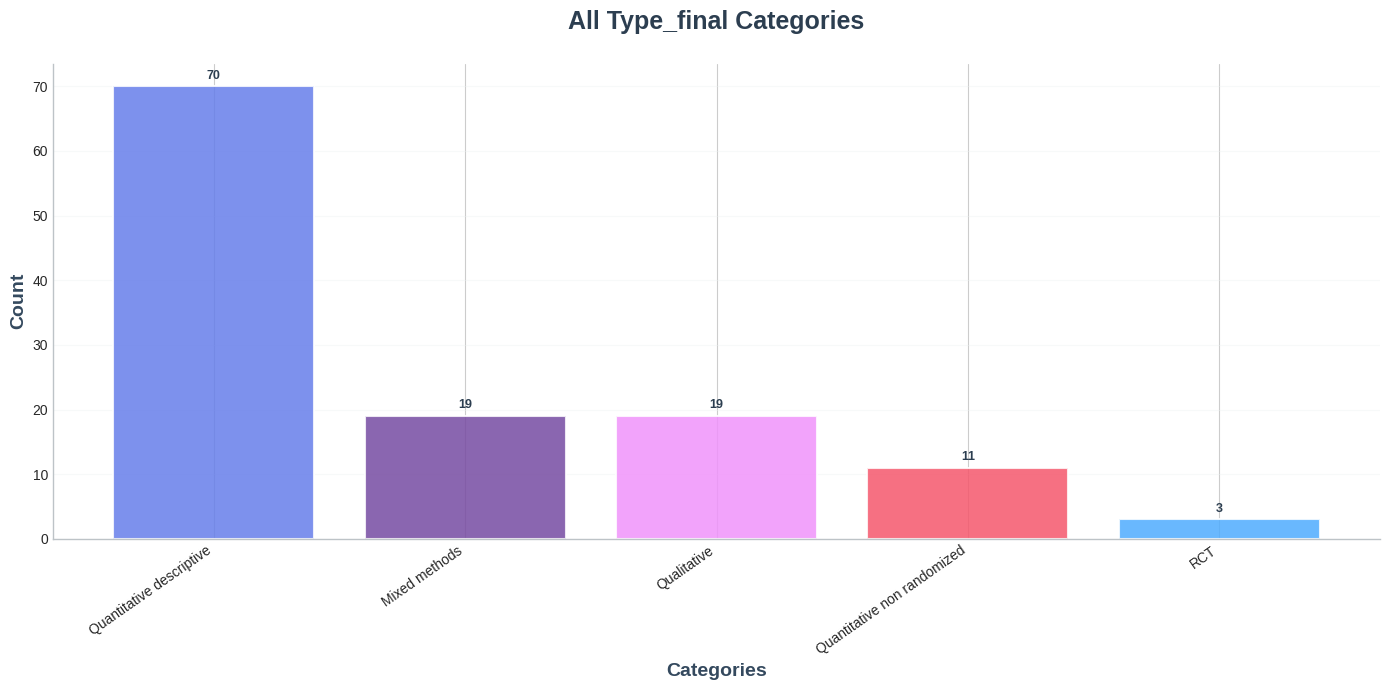

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_all_categories(df, column='TYPE', title=None):
    """
    Plot all categories (not only top 5) with modern styling
    """
    counts = df[column].value_counts()

    # Set modern style
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, ax = plt.subplots(figsize=(14, 7))

    # Modern color palette (cycled)
    base_colors = ['#667eea', '#764ba2', '#f093fb', '#f5576c', '#4facfe']
    colors = [base_colors[i % len(base_colors)] for i in range(len(counts))]

    # Create bars
    bars = ax.bar(range(len(counts)), counts.values,
                  color=colors, alpha=0.85, edgecolor='white', linewidth=1.5)

    # Add value labels on top
    for bar, value in zip(bars, counts.values):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + max(counts.values) * 0.01,
                f'{value:,}', ha='center', va='bottom',
                fontweight='bold', fontsize=9, color='#2c3e50')

    # Styling
    ax.set_title(title or f'All {column} Categories',
                 fontsize=18, fontweight='bold', pad=25, color='#2c3e50')
    ax.set_xlabel('Categories', fontsize=14, fontweight='600', color='#34495e')
    ax.set_ylabel('Count', fontsize=14, fontweight='600', color='#34495e')

    # Replace "_" with space in labels
    labels = [lbl.replace('_',' ') for lbl in counts.index]
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels(labels, rotation=35, ha='right', fontsize=10)

    # Remove spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#bdc3c7')
    ax.spines['bottom'].set_color('#bdc3c7')

    # Grid
    ax.grid(axis='y', alpha=0.4, linestyle='-', linewidth=0.8, color='#ecf0f1')
    ax.set_axisbelow(True)

    plt.tight_layout()
    return plt

plot_all_categories(df, 'Type_final')
plt.show()


In [ ]:

df.to_excel( "/content/drive/MyDrive/fix_systematic_review/MMAT/final_Type_jugment.xlsx")